In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

import seaborn as sns
from itertools import combinations


plt.style.use("default")
sns.set_theme(style="whitegrid")

# File path
PATH = "../../statsbomb_pipeline/data/processed/team/team_season.csv"

df = pd.read_csv(PATH)

# ---- Target ----
target_col = "xg_for"

# ---- Predictors (numeric only, remove IDs/wins/losses/draws) ----
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

drop_cols = [
    target_col,
    "team_id",
    "matches_played",
    "wins",
    "losses",
    "draws", 
    "xg_per_match"
]

predictor_cols = [c for c in numeric_cols if c not in drop_cols]

X = df[predictor_cols].copy()
y = df[target_col].copy()

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (16, 13) Test: (4, 13)


In [9]:
def run_multiple_regression(X_train, X_test, y_train, y_test, feature_list):
    """
    Fit multivariate regression y ~ feature_list.
    Safe version: adjusted R² will be NaN when sample size is too small.
    """
    model = LinearRegression()

    Xtr = X_train[feature_list]
    Xte = X_test[feature_list]

    model.fit(Xtr, y_train)

    # Predictions
    y_pred_train = model.predict(Xtr)
    y_pred_test = model.predict(Xte)

    # Metrics
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test = mean_squared_error(y_test, y_pred_test)

    rmse_train = mse_train ** 0.5
    rmse_test = mse_test ** 0.5

    # Adjusted R² (safe version)
    n_train = Xtr.shape[0]
    n_test = Xte.shape[0]
    p = len(feature_list)

    # TRAIN adj R²
    denom_train = n_train - p - 1
    if denom_train > 0:
        adj_r2_train = 1 - ((1 - r2_train) * (n_train - 1) / denom_train)
    else:
        adj_r2_train = np.nan

    # TEST adj R²
    denom_test = n_test - p - 1
    if denom_test > 0:
        adj_r2_test = 1 - ((1 - r2_test) * (n_test - 1) / denom_test)
    else:
        adj_r2_test = np.nan

    return {
        "features": feature_list,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "adj_r2_train": adj_r2_train,
        "adj_r2_test": adj_r2_test,
        "mse_train": mse_train,
        "mse_test": mse_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "model": model,
    }


In [ ]:


multi_results = []
multi_models = {}

# choose sizes of feature sets we want to test
sizes_to_try = [2, 3]

for k in sizes_to_try:
    for combo in combinations(predictor_cols, k):
        feature_list = list(combo)
        res = run_multiple_regression(X_train, X_test, y_train, y_test, feature_list)

        # store model separately
        key = tuple(feature_list)
        multi_models[key] = res["model"]

        # store metrics (without the model object)
        metrics_row = {
            "features": feature_list,
            "num_features": len(feature_list),
            "r2_train": res["r2_train"],
            "r2_test": res["r2_test"],
            "adj_r2_train": res["adj_r2_train"],
            "adj_r2_test": res["adj_r2_test"],
            "mse_train": res["mse_train"],
            "mse_test": res["mse_test"],
            "rmse_train": res["rmse_train"],
            "rmse_test": res["rmse_test"],
        }
        multi_results.append(metrics_row)

multi_results_df = pd.DataFrame(multi_results)

# sort by best test R^2
multi_results_df = multi_results_df.sort_values("r2_test", ascending=False).reset_index(drop=True)

print("Top 10 models by test R^2:")
display(multi_results_df.head(10))

# get top 3 models
top3 = multi_results_df.head(3)
top3


Top 10 models by test R^2:


,features,num_features,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
0,"[goals_for, carries_for, ppa_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
1,"[goals_for, carries_for, ppa_for]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
2,"[carries_for, ppa_for, goals_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
3,"[carries_for, goals_per_match, ppa_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
4,"[goals_for, passes_for, ppa_per_match]",3,0.947912,0.848347,0.934890,NaN,4.749187,20.726059,2.179263,4.552588
5,"[goals_for, passes_for, ppa_for]",3,0.947912,0.848347,0.934890,NaN,4.749187,20.726059,2.179263,4.552588
6,"[passes_for, ppa_for, goals_per_match]",3,0.947912,0.848347,0.934890,NaN,4.749187,20.726059,2.179263,4.552588
7,"[passes_for, goals_per_match, ppa_per_match]",3,0.947912,0.848347,0.934890,NaN,4.749187,20.726059,2.179263,4.552588
8,"[ppa_for, goals_per_match, f3_entries_per_match]",3,0.947785,0.848011,0.934731,NaN,4.760837,20.772076,2.181934,4.557639
9,"[f3_entries_for, goals_per_match, ppa_per_match]",3,0.947785,0.848011,0.934731,NaN,4.760837,20.772076,2.181934,4.557639


,features,num_features,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
0,"[goals_for, carries_for, ppa_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
1,"[goals_for, carries_for, ppa_for]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
2,"[carries_for, ppa_for, goals_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074


In [11]:
print("=== Top 3 Multiple Regression Models (by test R^2) ===")
cols_to_show = [
    "features",
    "num_features",
    "r2_train", "r2_test",
    "adj_r2_train", "adj_r2_test",
    "mse_train", "mse_test",
    "rmse_train", "rmse_test",
]
display(top3[cols_to_show])


=== Top 3 Multiple Regression Models (by test R^2) ===


,features,num_features,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
0,"[goals_for, carries_for, ppa_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
1,"[goals_for, carries_for, ppa_for]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074
2,"[carries_for, ppa_for, goals_per_match]",3,0.949385,0.860071,0.936731,NaN,4.614895,19.123776,2.148231,4.373074



=== Model 1: Features = ['goals_for', 'carries_for', 'ppa_per_match'] ===
R^2 test: 0.8601, RMSE test: 4.3731


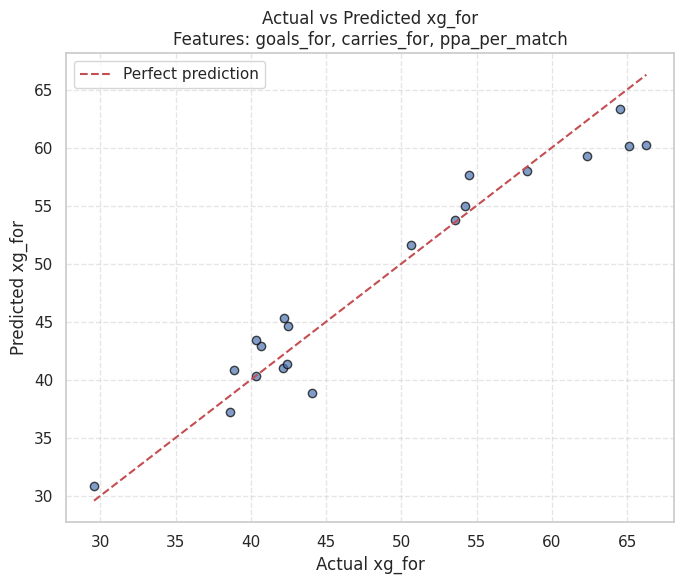

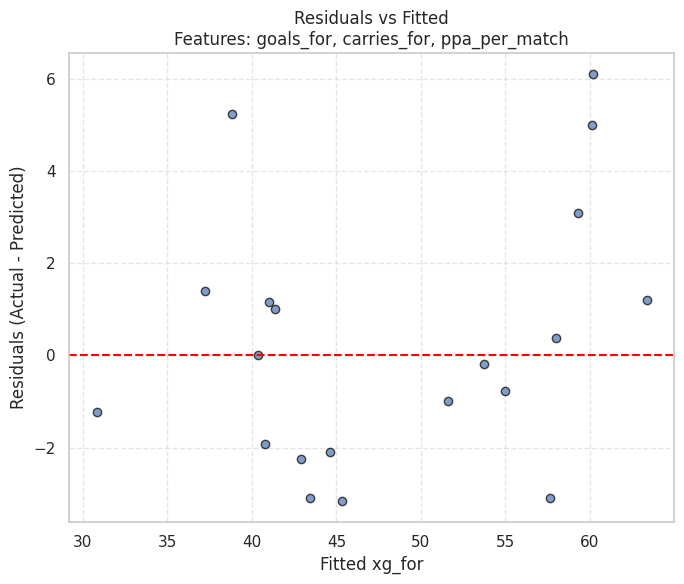


=== Model 2: Features = ['goals_for', 'carries_for', 'ppa_for'] ===
R^2 test: 0.8601, RMSE test: 4.3731


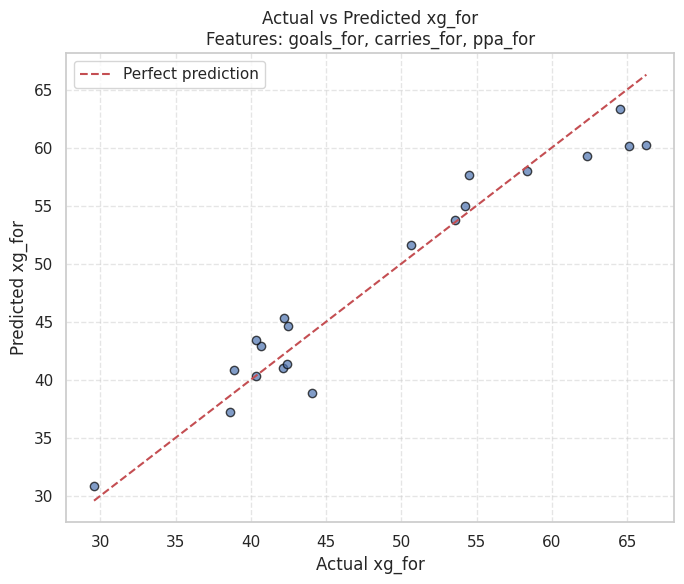

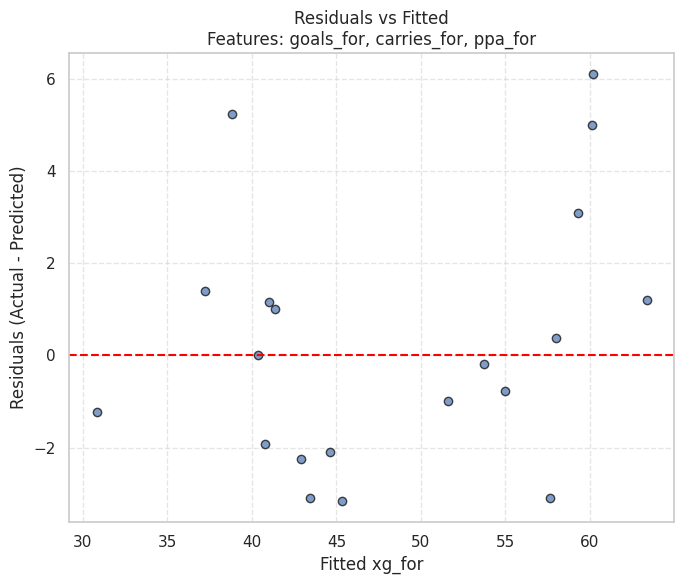


=== Model 3: Features = ['carries_for', 'ppa_for', 'goals_per_match'] ===
R^2 test: 0.8601, RMSE test: 4.3731


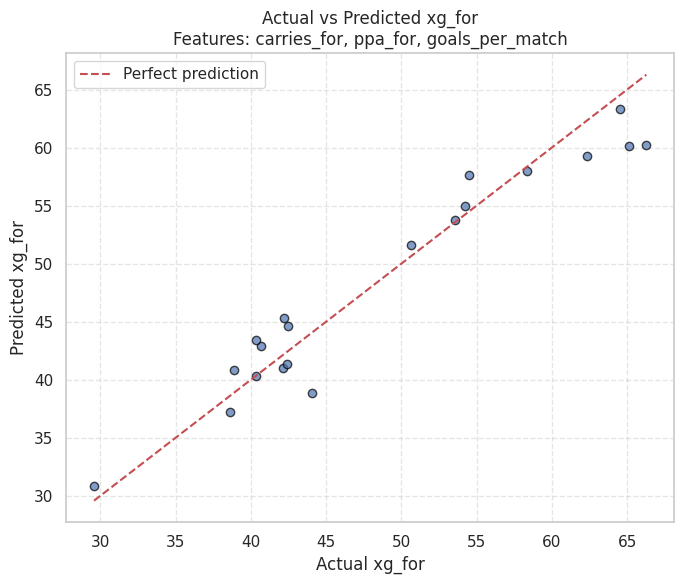

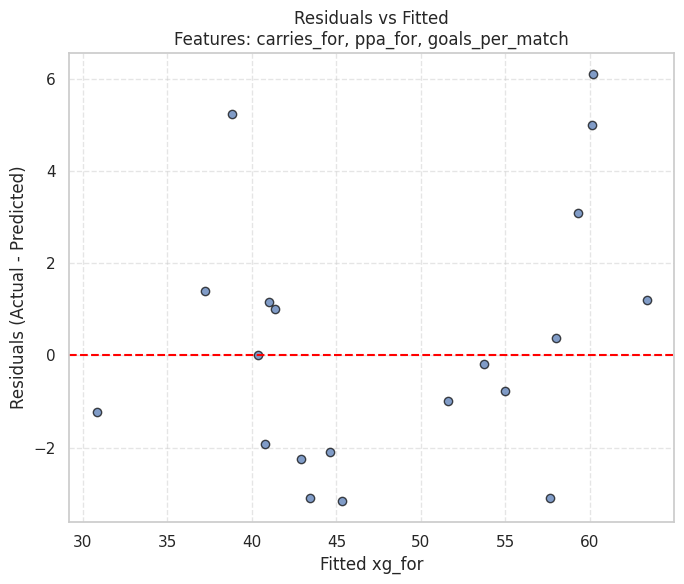

In [ ]:

def plot_model_diagnostics(feature_list, model, X_train, X_test, y_train, y_test, target_name="xg_for"):
    # Build full X and y for plotting
    X_all = pd.concat([X_train[feature_list], X_test[feature_list]], axis=0)
    y_all = pd.concat([y_train, y_test], axis=0)

    # Predictions
    y_pred_all = model.predict(X_all)

    # Residuals
    residuals = y_all - y_pred_all

    # --- 1) Actual vs Predicted ---
    plt.figure(figsize=(7, 6))
    plt.scatter(y_all, y_pred_all, alpha=0.7, edgecolor="black")
    line_min = min(y_all.min(), y_pred_all.min())
    line_max = max(y_all.max(), y_pred_all.max())
    plt.plot([line_min, line_max], [line_min, line_max], "r--", label="Perfect prediction")

    plt.xlabel(f"Actual {target_name}")
    plt.ylabel(f"Predicted {target_name}")
    plt.title(f"Actual vs Predicted {target_name}\nFeatures: {', '.join(feature_list)}")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # --- 2) Residuals vs Fitted ---
    plt.figure(figsize=(7, 6))
    plt.scatter(y_pred_all, residuals, alpha=0.7, edgecolor="black")
    plt.axhline(0, color="red", linestyle="--")

    plt.xlabel(f"Fitted {target_name}")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(f"Residuals vs Fitted\nFeatures: {', '.join(feature_list)}")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# Loop over the top 3 models and plot diagnostics
for idx, row in top3.iterrows():
    feature_list = row["features"]
    key = tuple(feature_list)
    model = multi_models[key]

    print(f"\n=== Model {idx+1}: Features = {feature_list} ===")
    print(f"R^2 test: {row['r2_test']:.4f}, RMSE test: {row['rmse_test']:.4f}")
    plot_model_diagnostics(feature_list, model, X_train, X_test, y_train, y_test, target_name="xg_for")
